# Explore the AI money loop data
Scratch notebook. `ai_money_loop.ipynb` is the presentation copy that builds the figures; this one loads the same files into DataFrames and gives you helpers to re-cut them. Run the first cell, then use any section on its own.

Every function takes the DataFrame as an argument, so you can filter a copy and pass it in without touching the files on disk. The last section appends rows to the CSVs, with the source fields required.

In [1]:
import pandas as pd, numpy as np, networkx as nx, matplotlib.pyplot as plt, pathlib, json
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 60)
D = pathlib.Path("data"); F = pathlib.Path("figures")
C = {"MSFT": "#2a78d6", "GOOGL": "#eb6834", "AMZN": "#1baf7a", "META": "#eda100", "CRWV": "#2a78d6", "NBIS": "#eb6834",
     "IREN": "#1baf7a", "APLD": "#eda100", "NVDA": "#0b0b0b", "ink": "#0b0b0b", "muted": "#898781"}
NAMES = {"MSFT": "Microsoft", "GOOGL": "Alphabet", "AMZN": "Amazon", "META": "Meta", "CRWV": "CoreWeave", "NBIS": "Nebius",
         "IREN": "IREN", "APLD": "Applied Digital", "NVDA": "Nvidia"}

deals = pd.read_csv(D / "deals.csv", dtype=str, keep_default_na=False)
deals["amount_usd_bn"] = pd.to_numeric(deals.amount_usd_bn, errors="coerce")
cashflow = pd.read_csv(D / "hyperscaler_cashflow.csv", parse_dates=["quarter"])
neo = pd.read_csv(D / "neocloud_financials.csv", parse_dates=["quarter"])
segments = pd.read_csv(D / "segment_revenue.csv", parse_dates=["quarter_end"])
btos_use = pd.read_csv(D / "btos_ai_use.csv", parse_dates=["ref_end"]); btos_plan = pd.read_csv(D / "btos_ai_plan.csv", parse_dates=["ref_end"])
prices = pd.read_csv(D / "prices.csv", parse_dates=["Date"]).set_index("Date")
pulled = json.load(open(D / "pull_meta.json"))["pulled_utc"]

for name, df in [("deals", deals), ("cashflow", cashflow), ("neo", neo), ("segments", segments), ("btos_use", btos_use), ("prices", prices)]:
    print(f"{name:10s} {df.shape[0]:4d} rows x {df.shape[1]:2d} cols   columns: {', '.join(map(str, df.columns[:8]))}{' ...' if df.shape[1] > 8 else ''}")
print("pulled", pulled)

deals        50 rows x  9 cols   columns: from, to, type, amount_usd_bn, date, status, source_url, quote ...
cashflow     21 rows x  5 cols   columns: ticker, quarter, capex, ocf, fcf
neo          25 rows x  9 cols   columns: ticker, quarter, total_debt, net_debt, cash, revenue, op_income, interest_expense ...
segments     88 rows x 10 cols   columns: ticker, segment, metric, quarter_end, value, unit, source_url, quote ...
btos_use     24 rows x  3 cols   columns: smpdt, pct, ref_end
prices      458 rows x 12 cols   columns: AMD, AMZN, APLD, CRWV, GOOGL, IREN, META, MSFT ...
pulled 2026-10-30T02:19+00:00


## 1. The deal graph: what-ifs on the loop
`loop_summary` rebuilds the graph the way `money_loop.py` does and reports the closed-loop dollars. Change `statuses` to let `conditional` rows in, pass `drop` to remove edges, or hand it a filtered copy of `deals`.

In [2]:
ALIAS = {"Amazon (AWS)": "Amazon", "Google Cloud": "Google", "bond investors": "Credit markets", "convertible investors": "Credit markets"}

def build_graph(df, statuses=("LOI", "committed", "funded"), drop=()):
    """drop: iterable of (from, to) pairs to leave out, after aliasing."""
    g = df[~df.type.isin(["capex_guidance", "capex_actual"]) & df.status.isin(statuses) & (df.to != "")].copy()
    excl = ((g["from"] == "Nvidia") & (g["to"] == "OpenAI") & (g.amount_usd_bn == 100)) | g["from"].str.contains(";") | (g["from"] == "SK Group")
    g = g[~excl]
    g["from"] = g["from"].replace(ALIAS); g["to"] = g["to"].replace(ALIAS)
    g = g[~g.apply(lambda r: (r["from"], r["to"]) in set(drop), axis=1)]
    G = nx.DiGraph()
    for _, r in g.iterrows():
        w = 0.0 if pd.isna(r.amount_usd_bn) else float(r.amount_usd_bn)
        if G.has_edge(r["from"], r["to"]): G[r["from"]][r["to"]]["w"] += w
        else: G.add_edge(r["from"], r["to"], w=w)
    return G

def loop_summary(df=deals, statuses=("LOI", "committed", "funded"), drop=(), top=5):
    G = build_graph(df, statuses, drop)
    cycles = list(nx.simple_cycles(G))
    on = {e for c in cycles for e in zip(c, c[1:] + c[:1])}
    loop = sum(G[a][b]["w"] for a, b in on); total = sum(d["w"] for *_, d in G.edges(data=True))
    rows = sorted(((" -> ".join(c + [c[0]]), sum(G[c[i]][c[(i + 1) % len(c)]]["w"] for i in range(len(c)))) for c in cycles), key=lambda r: -r[1])
    print(f"{G.number_of_edges()} edges, {len(cycles)} cycles, ${loop:.0f}bn of ${total:.0f}bn on a loop ({loop / total:.0%})")
    return pd.DataFrame(rows[:top], columns=["cycle", "sum_edges_bn"])

print("baseline"); display(loop_summary())
print("\nif Amazon's $35bn conditional tranche counted"); display(loop_summary(statuses=("LOI", "committed", "funded", "conditional")))
print("\nwithout the OpenAI -> Microsoft $250bn contract"); display(loop_summary(drop=[("OpenAI", "Microsoft")]))

baseline
24 edges, 9 cycles, $468bn of $610bn on a loop (77%)


,cycle,sum_edges_bn
0,Microsoft -> Anthropic -> Amazon -> OpenAI -> Microsoft,370.0
1,Microsoft -> OpenAI -> Microsoft,261.8
2,Nvidia -> Anthropic -> Amazon -> OpenAI -> Nvidia,125.0
3,Anthropic -> Amazon -> Anthropic,113.0
4,Nvidia -> Anthropic -> Microsoft -> OpenAI -> Nvidia,51.8



if Amazon's $35bn conditional tranche counted
24 edges, 9 cycles, $503bn of $645bn on a loop (78%)


,cycle,sum_edges_bn
0,Microsoft -> Anthropic -> Amazon -> OpenAI -> Microsoft,405.0
1,Microsoft -> OpenAI -> Microsoft,261.8
2,Nvidia -> Anthropic -> Amazon -> OpenAI -> Nvidia,160.0
3,Anthropic -> Amazon -> Anthropic,113.0
4,Nvidia -> Anthropic -> Microsoft -> OpenAI -> Nvidia,51.8



without the OpenAI -> Microsoft $250bn contract
23 edges, 7 cycles, $218bn of $360bn on a loop (60%)


,cycle,sum_edges_bn
0,Nvidia -> Anthropic -> Amazon -> OpenAI -> Nvidia,125.0
1,Anthropic -> Amazon -> Anthropic,113.0
2,Nvidia -> Anthropic -> Microsoft -> OpenAI -> Nvidia,51.8
3,Anthropic -> Microsoft -> Anthropic,35.0
4,Nvidia -> OpenAI -> Nvidia,30.0


## 2. Capex against free cash flow
`capex_table` pivots the cash-flow feed; `plot_capex_vs` draws any set of tickers on one axis.

ticker,AMZN,GOOGL,META,MSFT
quarter,,,,
2025-03-31,25.0,NaN,NaN,NaN
2025-06-30,32.2,22.4,NaN,17.1
2025-09-30,35.1,24.0,18.8,19.4
2025-12-31,39.5,27.9,21.4,29.9
2026-03-31,44.2,35.7,19.0,30.9
2026-06-30,NaN,44.9,30.1,35.8
2026-09-30,NaN,NaN,33.9,NaN


ticker,AMZN,GOOGL,META,MSFT
quarter,,,,
2025-03-31,-8.0,NaN,NaN,NaN
2025-06-30,0.3,5.3,NaN,25.6
2025-09-30,0.4,24.5,11.2,25.7
2025-12-31,14.9,24.6,14.8,5.9
2026-03-31,-18.2,10.1,13.2,15.8
2026-06-30,NaN,-5.9,1.7,19.6
2026-09-30,NaN,NaN,-1.2,NaN


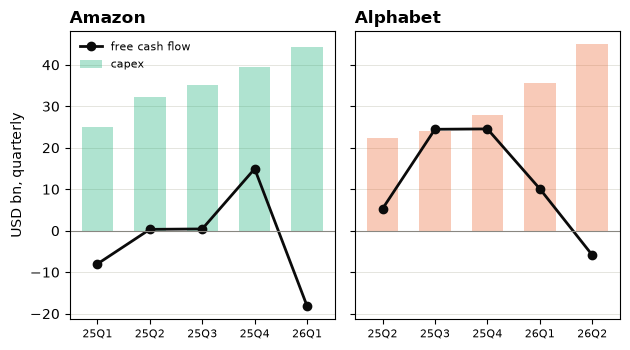

In [3]:
def capex_table(df=cashflow, since="2025-01-01", value="capex"):
    return df[df.quarter >= since].pivot(index="quarter", columns="ticker", values=value).round(1)

def plot_capex_vs(*tickers, df=cashflow, since="2025-01-01"):
    tickers = tickers or ("MSFT", "GOOGL", "AMZN", "META")
    fig, axes = plt.subplots(1, len(tickers), figsize=(3.2 * len(tickers), 3.6), sharey=True, squeeze=False)
    for ax, t in zip(axes[0], tickers):
        d = df[(df.ticker == t) & (df.quarter >= since)].dropna(subset=["capex"]).reset_index(drop=True); x = np.arange(len(d))
        ax.bar(x, d.capex, width=0.6, color=C.get(t, C["muted"]), alpha=0.35, label="capex")
        ax.plot(x, d.fcf, color=C["ink"], marker="o", lw=2, label="free cash flow"); ax.axhline(0, color=C["muted"], lw=0.8)
        ax.set_xticks(x); ax.set_xticklabels([f"{q.year % 100}Q{(q.month - 1) // 3 + 1}" for q in d.quarter], fontsize=8)
        ax.set_title(NAMES.get(t, t), loc="left", fontweight="bold"); ax.grid(axis="y", color="#e1e0d9", lw=0.6); ax.set_axisbelow(True)
    axes[0][0].set_ylabel("USD bn, quarterly"); axes[0][0].legend(frameon=False, fontsize=8); fig.tight_layout(); return fig

display(capex_table()); display(capex_table(value="fcf"))
plot_capex_vs("AMZN", "GOOGL");

## 3. Segment revenue against capex
`ratio_table` reproduces the dashboard's number: year-over-year change in trailing-four-quarter segment revenue, divided by trailing-four-quarter capex, both ending at `end` (default: the last quarter where both exist). `plot_segment` overlays the segment line on the capex bars.

,ticker,segment,window_end,t4_capex,new_seg_revenue,new_seg_op_income,rev_per_capex
0,MSFT,Intelligent Cloud,2026-06-30,115.9,31.5,12.4,0.27
1,GOOGL,Google Cloud,2026-06-30,132.4,28.4,15.3,0.21
2,AMZN,AWS,2026-03-31,151.0,25.3,6.5,0.17
3,META,Advertising,2026-09-30,104.4,50.8,-1.9,0.49


,ticker,segment,window_end,t4_capex,new_seg_revenue,new_seg_op_income,rev_per_capex,note
0,MSFT,Intelligent Cloud,2026-03-31,97.2,28.2,10.9,0.29,NaN
1,GOOGL,Google Cloud,2026-03-31,109.9,20.6,10.9,0.19,NaN
2,AMZN,AWS,2026-03-31,151.0,25.3,6.5,0.17,NaN
3,META,Advertising,2026-03-31,NaN,NaN,NaN,NaN,not enough quarters


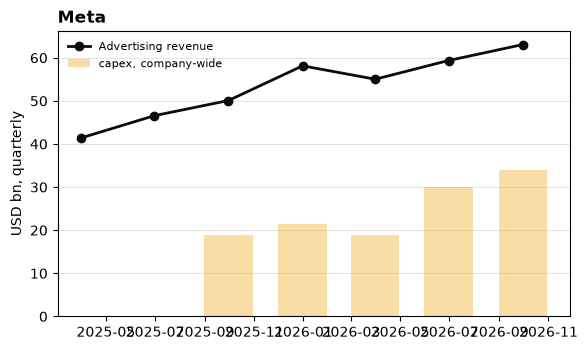

In [4]:
SEGMENT = {"MSFT": "Intelligent Cloud", "GOOGL": "Google Cloud", "AMZN": "AWS", "META": "Advertising"}

def ratio_table(end=None, seg=segments, cf=cashflow):
    rows = []
    for t, name in SEGMENT.items():
        rev = seg[(seg.ticker == t) & (seg.metric == "segment_revenue")].set_index("quarter_end").value.sort_index()
        opi = seg[(seg.ticker == t) & (seg.metric == "segment_operating_income")].set_index("quarter_end").value.sort_index()
        cap = cf[cf.ticker == t].set_index("quarter").capex.dropna().sort_index()
        e = pd.Timestamp(end) if end else min(rev.index.max(), cap.index.max())
        r, o, c = rev.loc[:e], opi.loc[:e], cap.loc[:e]
        if len(r) < 8 or len(c) < 4: rows.append(dict(ticker=t, segment=name, window_end=e.date(), note="not enough quarters")); continue
        d_rev = r.iloc[-4:].sum() - r.iloc[-8:-4].sum(); d_opi = o.iloc[-4:].sum() - o.iloc[-8:-4].sum() if len(o) >= 8 else np.nan; c4 = c.iloc[-4:].sum()
        rows.append(dict(ticker=t, segment=name, window_end=e.date(), t4_capex=round(c4, 1), new_seg_revenue=round(d_rev, 1), new_seg_op_income=round(d_opi, 1), rev_per_capex=round(d_rev / c4, 2)))
    return pd.DataFrame(rows)

def plot_segment(t, seg=segments, cf=cashflow, since="2025-01-01"):
    rev = seg[(seg.ticker == t) & (seg.metric == "segment_revenue") & (seg.quarter_end >= since)].sort_values("quarter_end")
    cap = cf[(cf.ticker == t) & (cf.quarter >= since)].dropna(subset=["capex"]).sort_values("quarter")
    fig, ax = plt.subplots(figsize=(6, 3.6))
    ax.bar(cap.quarter, cap.capex, width=60, color=C[t], alpha=0.35, label="capex, company-wide")
    ax.plot(rev.quarter_end, rev.value, color=C["ink"], marker="o", lw=2, label=f"{SEGMENT[t]} revenue")
    ax.set_title(NAMES[t], loc="left", fontweight="bold"); ax.set_ylabel("USD bn, quarterly"); ax.legend(frameon=False, fontsize=8)
    ax.grid(axis="y", color="#e1e0d9", lw=0.6); ax.set_axisbelow(True); fig.tight_layout(); return fig

display(ratio_table()); display(ratio_table(end="2026-03-31"))
plot_segment("META");

## 4. Neoclouds: balance sheets and price paths
`coverage` is the latest-quarter table (debt here is Yahoo's "Total Debt", which includes lease liabilities). `plot_indexed` rebases any tickers to 100 at `start`.

,ticker,quarter,total_debt,revenue,op_income,interest_expense,interest_coverage,debt_to_annualized_rev
0,CRWV,2026-06-30,51.61,2.58,-0.05,0.64,-0.08,5.01
1,IREN,2026-06-30,7.84,0.14,-0.14,0.02,-5.75,14.28
2,NBIS,2026-06-30,10.17,0.58,-0.18,0.12,-1.48,4.37
3,APLD,2026-08-31,6.48,0.34,-0.06,0.08,-0.81,4.74


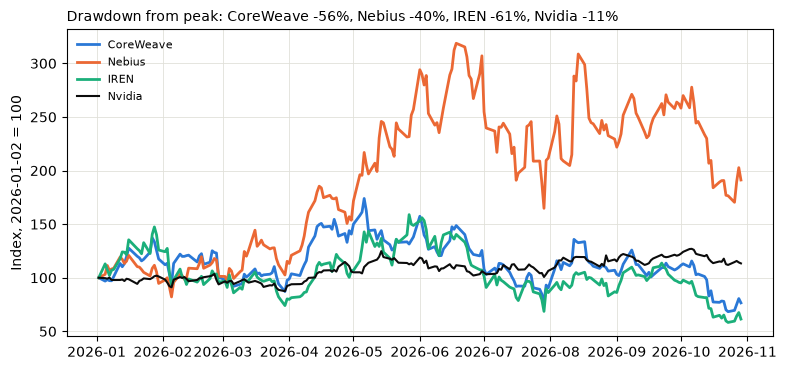

In [5]:
def coverage(df=neo):
    d = df.dropna(subset=["total_debt"]).sort_values("quarter").groupby("ticker").tail(1).copy()
    d["interest_coverage"] = (d.op_income / d.interest_expense).round(2); d["debt_to_annualized_rev"] = (d.total_debt / (d.revenue * 4)).round(2)
    out = d[["ticker", "quarter", "total_debt", "revenue", "op_income", "interest_expense", "interest_coverage", "debt_to_annualized_rev"]].reset_index(drop=True)
    num = out.columns.drop(["ticker", "quarter"]); out[num] = out[num].round(2); return out

def plot_indexed(tickers=("CRWV", "NBIS", "IREN", "NVDA"), start=None, px=prices):
    p = px[list(tickers)].dropna(); p = p[p.index >= start] if start else p; idx = p / p.iloc[0] * 100
    fig, ax = plt.subplots(figsize=(8, 3.8))
    for t in tickers: ax.plot(idx.index, idx[t], lw=2 if t != "NVDA" else 1.5, color=C.get(t, C["muted"]), label=NAMES.get(t, t))
    dd = (idx / idx.cummax() - 1).iloc[-1] * 100
    ax.set_title("Drawdown from peak: " + ", ".join(f"{NAMES.get(t, t)} {dd[t]:.0f}%" for t in tickers), loc="left", fontsize=10)
    ax.set_ylabel(f"Index, {idx.index[0].date()} = 100"); ax.legend(frameon=False, fontsize=8); ax.grid(color="#e1e0d9", lw=0.6); fig.tight_layout(); return fig

display(coverage())
plot_indexed(start="2026-01-01");

## 5. Adoption
Census BTOS, national. `btos_use` and `btos_plan` are already loaded; the question changed wording in November 2025, so the series starts there.

,smpdt,pct,ref_end
20,202618,23.2,2026-08-23
21,202619,23.8,2026-09-06
22,202620,23.8,2026-09-20
23,202621,24.6,2026-10-04


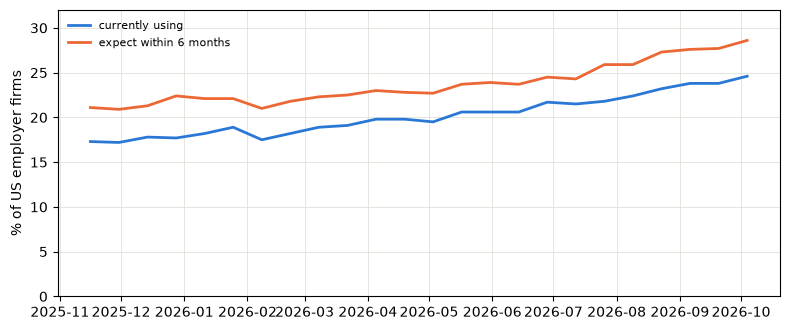

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(btos_use.ref_end, btos_use.pct, color=C["MSFT"], lw=2, label="currently using"); ax.plot(btos_plan.ref_end, btos_plan.pct, color=C["GOOGL"], lw=2, label="expect within 6 months")
ax.set_ylabel("% of US employer firms"); ax.set_ylim(0, 32); ax.legend(frameon=False, fontsize=8); ax.grid(color="#e1e0d9", lw=0.6); fig.tight_layout()
btos_use.tail(4)

## 6. Break-even
`breakeven` is the dashboard formula: required new revenue = capex × (1 / life + return) ÷ margin. `sweep` tabulates it over useful life and margin so you can see how sensitive the number is.

In [7]:
CAPEX_2026 = deals[deals.type == "capex_guidance"].amount_usd_bn.sum()
VISIBLE = ratio_table().new_seg_revenue.sum()

def breakeven(capex=CAPEX_2026, life=5, ret=0.10, margin=0.30, visible=VISIBLE):
    need = capex * (1 / life + ret) / margin
    print(f"${capex:.0f}bn x (1/{life} + {ret:.0%}) / {margin:.0%} = ${need:.0f}bn a year needed; ${visible:.0f}bn of new segment revenue visible ({visible / need:.0%})")
    return need

def sweep(capex=CAPEX_2026, lives=(3, 4, 5, 6, 8), margins=(0.2, 0.3, 0.4, 0.5), ret=0.10):
    return pd.DataFrame({f"{m:.0%} margin": [round(capex * (1 / L + ret) / m) for L in lives] for m in margins}, index=[f"{L}-yr life" for L in lives])

breakeven(); breakeven(life=6, margin=0.4)
sweep()

$735bn x (1/5 + 10%) / 30% = $735bn a year needed; $136bn of new segment revenue visible (19%)
$735bn x (1/6 + 10%) / 40% = $490bn a year needed; $136bn of new segment revenue visible (28%)


,20% margin,30% margin,40% margin,50% margin
3-yr life,1592,1062,796,637
4-yr life,1286,858,643,514
5-yr life,1102,735,551,441
6-yr life,980,653,490,392
8-yr life,827,551,413,331


## 7. Add a row
Both helpers refuse a row without a source URL and a quote, then append to the CSV on disk. Re-run `pull_data.py`-independent scripts (`money_loop.py`, `build_dashboard.py`) afterwards to see the row in the figures. The example calls are commented out so this cell is safe to run.

In [8]:
def add_deal(frm, to, type_, amount_bn, date, status, source_url, quote, note=""):
    assert source_url.startswith("http") and len(quote) > 10, "every row needs a source URL and a quote from that page"
    assert status in {"LOI", "committed", "funded", "conditional", "unverified"}, "unknown status"
    row = pd.DataFrame([dict(**{"from": frm, "to": to}, type=type_, amount_usd_bn=amount_bn, date=date, status=status, source_url=source_url, quote=quote, note=note)])
    row.to_csv(D / "deals.csv", mode="a", header=False, index=False, quoting=1); print("appended to data/deals.csv:", frm, "->", to, amount_bn)

def add_segment(ticker, segment, metric, quarter_end, value_bn, source_url, quote, release_date, note=""):
    assert source_url.startswith("http") and len(quote) > 10, "every row needs a source URL and a quote from that page"
    row = pd.DataFrame([dict(ticker=ticker, segment=segment, metric=metric, quarter_end=quarter_end, value=value_bn, unit="USD bn", source_url=source_url, quote=quote, release_date=release_date, note=note)])
    row.to_csv(D / "segment_revenue.csv", mode="a", header=False, index=False, quoting=1); print("appended to data/segment_revenue.csv:", ticker, metric, quarter_end, value_bn)

# add_deal("Oracle", "OpenAI", "cloud_contract", 300, "2025-09-10", "unverified", "https://...", "quoted sentence from the page", "WSJ-sourced")
# add_segment("AMZN", "AWS", "segment_revenue", "2026-12-31", 50.0, "https://www.sec.gov/...", "AWS segment sales increased ...", "2027-02-04")
print("helpers defined; uncomment an example to append a row")

helpers defined; uncomment an example to append a row
